In [ ]:
#Siddiqa Bagwan
#B24CE1093

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)

In [ ]:
iris=load_iris()

In [ ]:
X=iris.data
y=iris.target

In [ ]:
print("dataset shape:",X.shape)
print("target classes:",iris.target_names)

dataset shape: (150, 4)
target classes: ['setosa' 'versicolor' 'virginica']


In [ ]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
df=pd.DataFrame(iris.data,columns=iris.feature_names)

df["Species"]=iris.target
print(df.head(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  
5        0  
6        0  
7        0  
8        0  


In [ ]:
print(df)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     Species  
0          0

In [ ]:
print("missing vals",np.isnan(X).sum())

missing vals 0


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)
print("training data",X_train.shape)
print("testing data",X_test.shape)

training data (120, 4)
testing data (30, 4)


In [ ]:
#feature scaling create scaler
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)

X_test_scaled=scaler.transform(X_test)

print("feature scaling completed")

feature scaling completed


In [ ]:
#knn model
knn=KNeighborsClassifier(n_neighbors=5)

#train
knn.fit(X_train_scaled,y_train)

#predict
y_pred_knn=knn.predict(X_test_scaled)

print("knn predictions:",y_pred_knn)

knn predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


In [ ]:
#decisiontree model
dt=DecisionTreeClassifier(random_state=42)

dt.fit(X_train,y_train)

y_pred_dt=dt.predict(X_test)

print("decision tree predictions:",y_pred_dt)

decision tree predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [ ]:
#model evaluation
print("knn accuracy",accuracy_score(y_test,y_pred_knn))
#print("knn precision",precision_score(y_test,y_pred_knn,average="macro"))
print("knn recall",recall_score(y_test,y_pred_knn,average="macro"))
print("knn f1-score",f1_score(y_test,y_pred_knn,average="macro"))

knn accuracy 0.9333333333333333
knn recall 0.9333333333333332
knn f1-score 0.9326599326599326


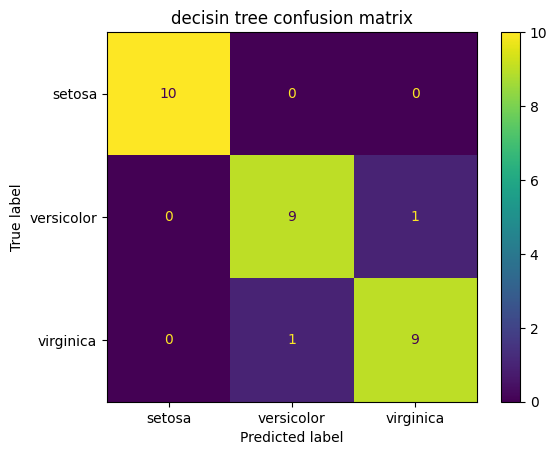

In [ ]:
#Plot Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm=confusion_matrix(y_test,y_pred_dt)

display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=iris.target_names)

display.plot()
plt.title("decisin tree confusion matrix")
plt.show()

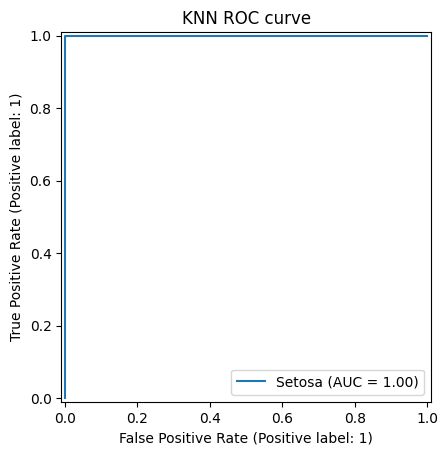

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# 1. Get prediction probabilities from KNN
y_prob_knn = knn.predict_proba(X_test_scaled)

# 2. Plot ROC curve (Note the corrected lowercase .astype)
RocCurveDisplay.from_predictions(
    (y_test == 0).astype(int),
    y_prob_knn[:, 0],
    name="Setosa"
)

# 3. Add titles and render
plt.title("KNN ROC curve")
plt.show()


In [ ]:
from sklearn.metrics import roc_auc_score

# Predict class probabilities using decision tree
y_prob_dt = dt.predict_proba(X_test)
print(y_prob_dt)

# Corrected roc_auc_score with missing comma and proper string formatting
auc_dt = roc_auc_score(y_test, y_prob_dt, multi_class='ovr', average='macro')
print("Decision tree AUC score", auc_dt)


[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]
Decision tree AUC score 0.9499999999999998


In [ ]:
#calculate auc for decision tree
auc_dt=roc_auc_score(y_test,y_prob_dt,multi_class="ovr",average="macro")
print("decision tree auc:",auc_dt)

decision tree auc: 0.9499999999999998


In [ ]:
print("KNN accuracy: ",accuracy_score(y_test, y_pred_knn))
print("Decision Tree accuracy: ",accuracy_score(y_test, y_pred_dt))
print("KNN F1-score: ",f1_score(y_test, y_pred_knn, average="macro"))
print("Decision Tree F1-score: ",f1_score(y_test, y_pred_dt, average="macro"))
print("KNN AUC: ",knn)
print("Decision tree AUC:",auc_dt)

KNN accuracy:  0.9333333333333333
Decision Tree accuracy:  0.9333333333333333
KNN F1-score:  0.9326599326599326
Decision Tree F1-score:  0.9333333333333332
KNN AUC:  KNeighborsClassifier()
Decision tree AUC: 0.9499999999999998
